# 문서와 메타데이터

**이 노트북에서 할 일**

1. 이 챕터가 읽을 문서 폴더를 열어 파일이 몇 건이고 형식이 몇 가지인지 셉니다.
2. Ch 9 로더로 E01.pdf를 읽고, 같은 쪽을 다른 방법으로 한 번 더 읽어 두 글을 견줍니다.
3. 다섯 칸 출처 기록을 만들고, 쪽 번호를 잘못 적었을 때와 바로 적었을 때를 견줍니다.

**준비물** — API 키가 필요 없습니다. 모델과 임베딩에는 요청을 한 번도 보내지 않습니다.
첫 셀의 패키지 설치만 인터넷을 씁니다.
그래서 예상 비용은 0달러입니다. 실행 시간은 패키지 설치를 빼면 10초 안팎입니다.

데이터는 두 곳입니다. `labs/data/rag-corpus/` 폴더의 PDF와 `labs/part3/ch10-document-processing/fixtures/` 폴더의 형식 견본입니다.

**강의와 실습 범위** — 강의 시간에는 2~6절을 설명합니다.
문서 폴더 살펴보기, Ch 9 로더, 두 가지 읽기, 다섯 칸 출처 기록입니다.
7절 값 바꿔 보기와 8~9절 Before·After는 함께 실행하고 실습 시간에 다시 읽습니다.

**기준 버전** — 실습 폴더에 고정한 패키지 판을 씁니다. pypdf 6.18.0, langchain-core 1.6.2입니다.
Ch 9 실습 폴더의 pypdf는 6.17.0이라 판이 다릅니다.
교재 출력은 Linux의 Python 3.12.13으로 만들었습니다. 다른 버전과 Windows·macOS에서는 이번에 실행하지 않았습니다.

실습 폴더 `labs/part3/ch10-document-processing`에서 `uv sync --locked`를 실행합니다.
그다음 이 폴더의 `.venv` 커널을 고르고 첫 셀부터 순서대로 실행합니다.

## 오늘 볼 그림

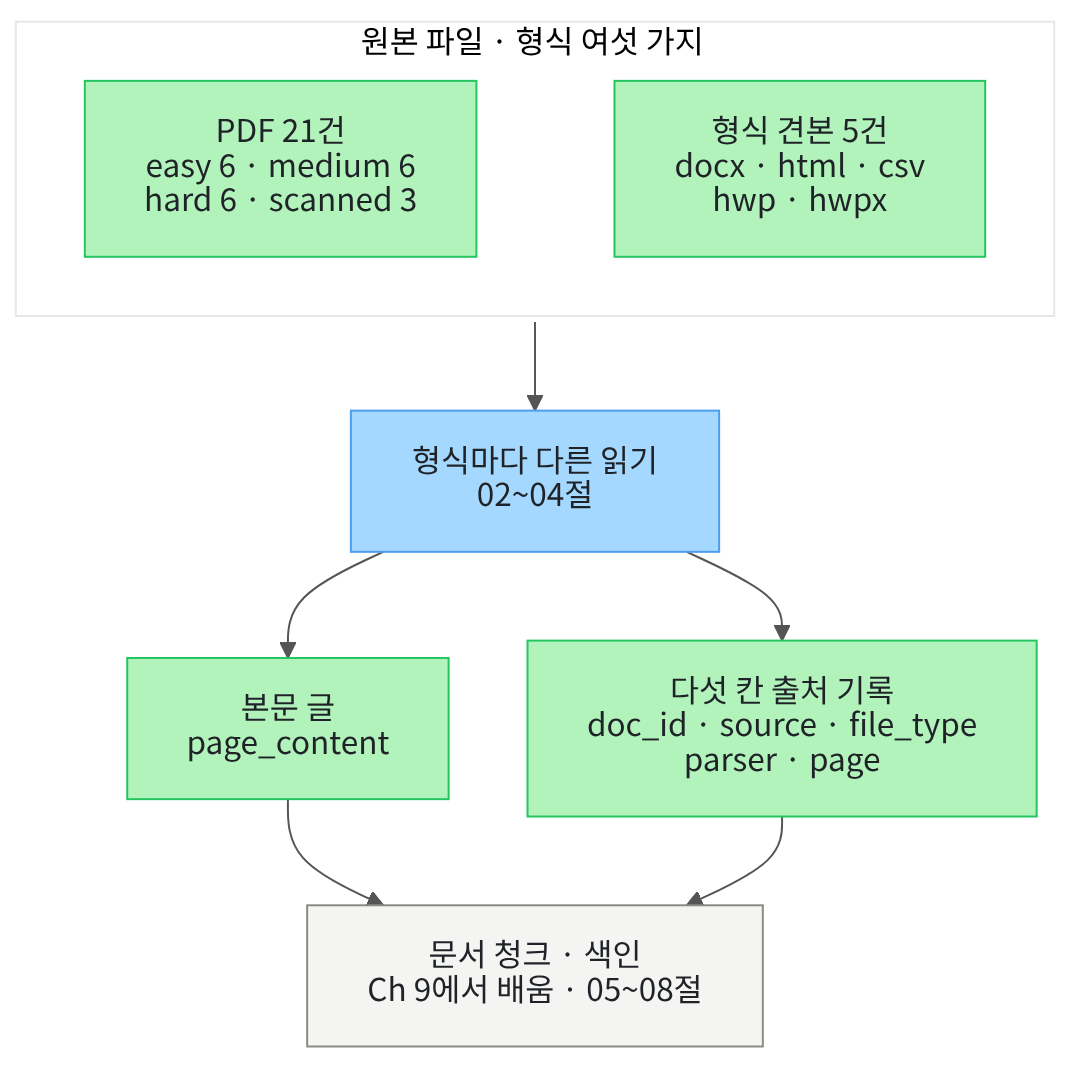

위 칸은 이 챕터가 읽을 원본 파일입니다. 형식은 여섯 가지이고 읽는 방법도 형식마다 다릅니다.
읽고 난 뒤에 남는 것은 본문 글과 다섯 칸 출처 기록 두 가지뿐입니다.
초록 상자는 파일과 기록, 파란 상자는 코드 단계, 회색 상자는 이 절에서 실행하지 않는 Ch 9 단계입니다.

## 1. 준비

첫 셀은 패키지를 설치하고 설치된 버전을 출력합니다. 설치에는 몇십 초가 걸릴 수 있습니다.
Ch 9와 같은 pypdf로 PDF를 읽고, 같은 `Document`로 본문과 메타데이터를 묶습니다.

In [1]:
# 이 절에서 쓰는 패키지를 설치하고 버전을 확인합니다
%pip install -q "pypdf==6.18.0" "langchain-core==1.6.2"
from importlib.metadata import version

print("pypdf:", version("pypdf"))
print("langchain-core:", version("langchain-core"))

Note: you may need to restart the kernel to use updated packages.
pypdf: 6.18.0
langchain-core: 1.6.2


**결과 읽기** — 출력 줄은 `pypdf: 6.18.0`과 `langchain-core: 1.6.2` 두 줄입니다.
준비물에 적은 기준 버전과 같습니다.

다음 셀은 이 절에서 쓸 이름을 불러옵니다.
클래스 `Path`는 파일 경로를 다루는 Python 기본 기능입니다.
경로 글자를 넣어 만들면 파일 이름과 확장자를 따로 읽을 수 있습니다.
Ch 9에서는 경로를 글자 그대로 다뤘습니다. 이 절에서는 2절에서 확장자를 볼 때 처음 쓰고, 5절에서 세 속성을 함께 씁니다.

In [2]:
# 파일 찾기·경로 속성 읽기·PDF 읽기·문서 객체 만들기에 쓸 이름을 불러옵니다
import os
from pathlib import Path

from pypdf import PdfReader
from langchain_core.documents import Document

## 2. 이 챕터가 읽을 문서 폴더 찾기

노트북을 연 폴더에 따라 문서 폴더까지 가는 경로가 다릅니다.
Ch 9 01절처럼 후보 경로를 차례로 확인하고, 있는 경로에서 멈춥니다.
함수 `os.path.exists()`는 경로를 받아 파일이나 폴더가 있으면 `True`를 반환합니다.

후보는 세 개입니다. 프로젝트 맨 위, 실습 폴더 맨 위, `notebooks` 폴더에서 연 경우입니다.
실행 전에 예상합니다. 프로젝트 맨 위에서 열었다면 첫째 후보를 고를 것입니다.

In [3]:
# 작업 폴더에서 본 프로젝트 맨 위 경로를 후보 세 개 가운데에서 고릅니다
candidates = [".", "../../..", "../../../.."]
root_path = None
for candidate in candidates:
    if os.path.exists(candidate + "/labs/data/rag-corpus"):
        root_path = candidate
        break
print("프로젝트 맨 위를 찾았는가:", root_path is not None)
print("고른 경로:", root_path)
assert root_path is not None, "notebooks 폴더나 실습 폴더 맨 위에서 노트북을 열어 주세요."

프로젝트 맨 위를 찾았는가: True
고른 경로: .


**결과 읽기** — 출력 줄은 `프로젝트 맨 위를 찾았는가: True`와 `고른 경로: .`입니다. `assert`도 통과했습니다.
교재 출력은 프로젝트 맨 위를 작업 폴더로 삼아 실행해서 첫째 후보를 골랐습니다.
`notebooks` 폴더에서 열면 셋째 후보, 실습 폴더 맨 위에서 열면 둘째 후보가 나옵니다.

다음 셀은 고른 경로에 폴더 이름을 이어 붙여 두 폴더 경로를 만듭니다.
그다음 PDF 폴더 네 개의 파일 수를 셉니다.
함수 `os.listdir()`은 폴더 경로를 받아 그 안 파일과 폴더 이름 목록을 반환합니다.

In [4]:
# 문서 폴더와 견본 폴더 경로를 만들고, 난이도 폴더 네 개의 PDF 수를 셉니다
corpus_path = root_path + "/labs/data/rag-corpus"
fixtures_path = root_path + "/labs/part3/ch10-document-processing/fixtures"
tier_names = ["easy", "medium", "hard", "scanned"]
print("폴더 | PDF 수:")
for tier_name in tier_names:
    file_names = os.listdir(corpus_path + "/pdf/" + tier_name)
    print(tier_name, "|", len(file_names))

폴더 | PDF 수:
easy | 6
medium | 6
hard | 6
scanned | 3


**결과 읽기** — 라벨 줄 `폴더 | PDF 수:` 아래 네 줄이 폴더마다 센 결과입니다.
`easy | 6`, `medium | 6`, `hard | 6`, `scanned | 3`이므로 PDF는 모두 21건입니다.
`scanned` 3건은 글자 층이 없는 스캔본이고, 02절에서 확인합니다.

다음 셀은 형식 견본 폴더를 봅니다. 여기에는 PDF가 아닌 파일이 들어 있습니다.
속성 `suffix`는 파일 이름 끝의 확장자를 점까지 붙여 반환합니다.

In [5]:
# 견본 폴더의 파일 이름과 확장자를 봅니다
fixture_names = sorted(os.listdir(fixtures_path))
print("견본 파일 | 확장자:")
for fixture_name in fixture_names:
    print(fixture_name, "|", Path(fixture_name).suffix)

견본 파일 | 확장자:
legacy-signature.hwp | .hwp
minimal-marker.hwpx | .hwpx
sample.csv | .csv
sample.docx | .docx
sample.html | .html


**결과 읽기** — 라벨 줄 `견본 파일 | 확장자:` 아래 다섯 줄이 견본 파일입니다.
확장자는 `.hwp`, `.hwpx`, `.csv`, `.docx`, `.html` 다섯 가지입니다.
PDF까지 세면 이 챕터가 읽을 형식은 여섯 가지입니다.
형식마다 파일을 읽는 도구가 다르고, 그 도구를 02~04절에서 하나씩 씁니다.

## 3. Ch 9 로더로 E01.pdf 읽기

Ch 9 02절에서 만든 로더 함수를 같은 코드로 가져옵니다.
이 함수는 PDF 경로와 문서 이름을 받아 쪽마다 `Document` 하나를 만듭니다.
메타데이터 칸은 `doc_id`, `page`, `source` 세 개입니다.

In [6]:
# PDF 경로와 문서 이름을 받아, 쪽마다 본문과 메타데이터를 담은 Document 목록을 반환하는 로더 함수를 정의합니다(Ch 9 02절과 같은 코드)
def load_pdf_pages(pdf_path, doc_id):
    reader = PdfReader(pdf_path)
    page_documents = []
    page_number = 1
    for page in reader.pages:
        metadata = {"doc_id": doc_id, "page": page_number, "source": doc_id + ".pdf"}
        page_document = Document(page_content=page.extract_text(), metadata=metadata)
        page_documents.append(page_document)
        page_number = page_number + 1
    return page_documents

**결과 읽기** — 이 셀은 함수를 만들기만 하므로 출력이 없습니다.

다음 셀에서 이 함수로 E01.pdf를 읽습니다.
문서 E01은 Ch 9 01~07절이 쓴 미르시립도서관 이용 안내 문서입니다.

In [7]:
# Ch 9 로더로 E01.pdf를 읽고 Document 수와 2쪽 메타데이터를 봅니다
pdf_path = corpus_path + "/pdf/easy/E01.pdf"
pages = load_pdf_pages(pdf_path, "E01")
print("Document 수:", len(pages))
print("2쪽 메타데이터:", pages[1].metadata)
print("2쪽 본문 글자 수:", len(pages[1].page_content))

Document 수: 5
2쪽 메타데이터: {'doc_id': 'E01', 'page': 2, 'source': 'E01.pdf'}
2쪽 본문 글자 수: 905


**결과 읽기** — 출력 줄은 `Document 수: 5`, `2쪽 메타데이터: {'doc_id': 'E01', 'page': 2, 'source': 'E01.pdf'}`, `2쪽 본문 글자 수: 905`입니다.
Ch 9 02절 출력과 같은 값입니다. 실습 폴더의 pypdf 판이 달라도 이 문서에서는 같은 글자 수가 나왔습니다.
목록 `pages`의 자리 1이 2쪽인 까닭은 로더가 쪽 번호를 1부터 세어 적기 때문입니다.

## 4. 같은 쪽을 다른 방법으로 한 번 더 읽기

PDF 파일은 글자를 쪽 위의 자리에 놓습니다.
그래서 같은 쪽이라도 어떤 순서로 글자를 이어 붙이느냐에 따라 결과가 달라집니다.
라이브러리 pypdf의 `extract_text()`는 자리 정보를 버리고 글자를 이어 붙입니다.
같은 메서드에 `extraction_mode="layout"`을 주면 빈칸과 줄 자리를 살려 이어 붙입니다.

실행 전에 예상합니다. 두 방법의 글자 수가 다를 것입니다.

In [8]:
# 같은 2쪽을 기본 읽기와 레이아웃 읽기로 읽어 글자 수와 줄 수를 봅니다
reader = PdfReader(pdf_path)
plain_text = reader.pages[1].extract_text()
layout_text = reader.pages[1].extract_text(extraction_mode="layout")
plain_lines = plain_text.split("\n")
layout_lines = layout_text.split("\n")
print("기본 읽기 글자 수:", len(plain_text))
print("기본 읽기 줄 수:", len(plain_lines))
print("레이아웃 읽기 글자 수:", len(layout_text))
print("레이아웃 읽기 줄 수:", len(layout_lines))

기본 읽기 글자 수: 905
기본 읽기 줄 수: 26
레이아웃 읽기 글자 수: 1396
레이아웃 읽기 줄 수: 51


**결과 읽기** — 출력 줄은 `기본 읽기 글자 수: 905`, `기본 읽기 줄 수: 26`입니다.
이어서 `레이아웃 읽기 글자 수: 1396`, `레이아웃 읽기 줄 수: 51`입니다.
레이아웃 읽기가 빈칸과 빈 줄을 더 넣어서 글자 수가 491자 많습니다.

다음 셀은 두 글에서 같은 문장을 찾아봅니다.
Ch 8 03절이 쓴 문장은 「매주 월요일은 정기 휴관일입니다」였습니다.

In [9]:
# 두 읽기에서 Ch 8이 쓴 문장 「정기 휴관일입니다」를 찾고, 「휴관」이 든 줄을 봅니다
closure_sentence = "정기 휴관일입니다"
print("기본 읽기에 있는가:", closure_sentence in plain_text)
print("레이아웃 읽기에 있는가:", closure_sentence in layout_text)
print("기본 읽기에서 「휴관」이 든 줄:")
for line in plain_lines:
    if "휴관" in line:
        print(line)
print("레이아웃 읽기에서 「휴관」이 든 줄:")
for line in layout_lines:
    if "휴관" in line:
        print(line)

기본 읽기에 있는가: False
레이아웃 읽기에 있는가: True
기본 읽기에서 「휴관」이 든 줄:
매주 월요일은 정기 휴관일 입니다. 법정 공휴일에도 휴관하며, 공휴일이 월요일과 겹치면 그 다음 날인
화요일에도 휴관합니다.
레이아웃 읽기에서 「휴관」이 든 줄:
매주 월요일은 정기 휴관일입니다. 법정 공휴일에도 휴관하며, 공휴일이 월요일과 겹치면 그 다음 날인
화요일에도 휴관합니다.


**결과 읽기** — 출력 줄은 `기본 읽기에 있는가: False`와 `레이아웃 읽기에 있는가: True`입니다.
라벨 줄 `기본 읽기에서 「휴관」이 든 줄:` 아래 첫 줄에 `정기 휴관일 입니다`가 있습니다. 「휴관일」과 「입니다」 사이에 빈칸이 들어갔습니다.
라벨 줄 `레이아웃 읽기에서 「휴관」이 든 줄:` 아래 첫 줄에는 `정기 휴관일입니다`로 빈칸 없이 붙어 있습니다.
Ch 9 01절도 기본 읽기에서 이 문장을 찾지 못해 `False`를 보았습니다.

읽는 방법 하나를 바꾸면 검색에 쓸 글이 이렇게 달라집니다.
그렇다면 Ch 9의 세 칸 기록은 두 결과를 어떻게 가려낼까요.

In [10]:
# Ch 9 로더가 만든 세 칸 기록을 두 읽기 결과에 그대로 붙일 수 있는지 봅니다
three_key_metadata = pages[1].metadata
print("세 칸 기록:", three_key_metadata)
print("두 읽기의 본문이 같은가:", plain_text == layout_text)
print("두 본문의 글자 수 차이:", len(layout_text) - len(plain_text))
print("이 기록에 읽은 방법을 적는 칸이 있는가:", "parser" in three_key_metadata)

세 칸 기록: {'doc_id': 'E01', 'page': 2, 'source': 'E01.pdf'}
두 읽기의 본문이 같은가: False
두 본문의 글자 수 차이: 491
이 기록에 읽은 방법을 적는 칸이 있는가: False


**결과 읽기** — 출력 줄은 `두 읽기의 본문이 같은가: False`와 `두 본문의 글자 수 차이: 491`입니다.
그런데 `세 칸 기록: {'doc_id': 'E01', 'page': 2, 'source': 'E01.pdf'}`은 두 결과에 똑같이 붙습니다.
마지막 줄 `이 기록에 읽은 방법을 적는 칸이 있는가: False`가 까닭입니다.
본문은 다른데 기록이 같으면, 나중에 어느 방법으로 읽은 글인지 되짚을 수 없습니다.

## 5. 다섯 칸 출처 기록 만들기

Ch 9는 PDF 한 가지만 다뤄서 세 칸으로 넉넉했습니다.
이 챕터는 형식이 여섯 가지이고 같은 형식에도 읽는 방법이 여럿입니다.
그래서 칸을 두 개 더 둡니다. 파일 형식을 적는 `file_type`과 읽은 방법을 적는 `parser`입니다.

세 칸 가운데 두 칸은 파일 경로에서 바로 얻을 수 있습니다.
속성 `name`은 확장자를 붙인 파일 이름, `stem`은 확장자를 뺀 이름, `suffix`는 확장자입니다.
점 뒤에 괄호가 없으면 저장된 값을 읽는 표기이고, `exists()`처럼 괄호가 있으면 검사를 실행하는 메서드입니다.

In [11]:
# 고른 PDF 경로에서 파일 이름·확장자를 뺀 이름·확장자를 읽습니다
pdf_path_object = Path(pdf_path)
print("경로 객체의 자료형:", type(pdf_path_object).__name__)
print("name:", pdf_path_object.name)
print("stem:", pdf_path_object.stem)
print("suffix:", pdf_path_object.suffix)

경로 객체의 자료형: PosixPath
name: E01.pdf
stem: E01
suffix: .pdf


**결과 읽기** — 출력 줄은 `경로 객체의 자료형: PosixPath`, `name: E01.pdf`, `stem: E01`, `suffix: .pdf`입니다.
이 이름은 Linux와 macOS에서 `PosixPath`이고 Windows에서는 다릅니다. 이번에는 Linux에서만 실행했습니다.
`stem` 값 `E01`이 Ch 9가 쓴 문서 이름과 같습니다. 이 문서 모음은 파일 이름 앞이 곧 문서 이름입니다.

다음 셀은 이 세 값에 쪽 번호와 읽은 방법을 더해 다섯 칸을 채우는 함수를 만듭니다.

In [12]:
# 파일 경로·쪽 번호·읽은 방법 이름을 받아 다섯 칸 출처 기록을 만들어 반환하는 함수를 정의합니다
def make_source_record(file_path, page, parser):
    path_object = Path(file_path)
    suffix = path_object.suffix
    file_type = suffix.replace(".", "").lower()
    record = {"doc_id": path_object.stem, "source": path_object.name,
              "file_type": file_type, "parser": parser, "page": page}
    return record

**결과 읽기** — 이 셀은 함수를 만들기만 하므로 출력이 없습니다.

`suffix` 값 `.pdf`에서 점을 빼고 소문자로 바꿔 `file_type` 칸에 넣습니다.
읽은 방법 이름은 사람이 정해 넘깁니다. 이번에는 pypdf의 기본 읽기라 `pypdf-plain`으로 적습니다.

In [13]:
# E01.pdf 2쪽을 기본 읽기로 읽은 결과의 출처 기록을 만듭니다
page_two_record = make_source_record(pdf_path, 2, "pypdf-plain")
print("출처 기록:", page_two_record)
print("기록의 칸 이름:", page_two_record.keys())
print("Ch 9 세 칸보다 늘어난 칸 수:", len(page_two_record) - len(three_key_metadata))

출처 기록: {'doc_id': 'E01', 'source': 'E01.pdf', 'file_type': 'pdf', 'parser': 'pypdf-plain', 'page': 2}
기록의 칸 이름: dict_keys(['doc_id', 'source', 'file_type', 'parser', 'page'])
Ch 9 세 칸보다 늘어난 칸 수: 2


**결과 읽기** — 출력 줄 `출처 기록:` 뒤에 `{'doc_id': 'E01', 'source': 'E01.pdf', 'file_type': 'pdf', 'parser': 'pypdf-plain', 'page': 2}`가 보입니다.
`기록의 칸 이름:` 줄에 다섯 칸 이름이 차례로 있고, `Ch 9 세 칸보다 늘어난 칸 수: 2`입니다.
같은 쪽을 레이아웃 읽기로 읽었다면 `parser` 칸에 `pypdf-layout`을 적습니다. 그 읽기는 02절에서 씁니다.

## 6. Ch 9 출처 표시 함수 그대로 쓰기

칸을 늘리면 앞 챕터 코드가 깨지지 않을지 걱정할 수 있습니다.
Ch 9 03절의 출처 표시 함수는 `doc_id`와 `page` 두 칸만 읽습니다.
그래서 칸이 늘어도 같은 코드가 그대로 동작합니다.

In [14]:
# 문서 청크 하나를 받아 [E01 p.2] 모양의 출처 표시를 만들어 반환하는 함수를 정의합니다(Ch 9 03절과 같은 코드)
def make_source_mark(chunk):
    doc_id = chunk.metadata["doc_id"]
    page = chunk.metadata["page"]
    source_mark = f"[{doc_id} p.{page}]"
    return source_mark

**결과 읽기** — 이 셀은 함수를 만들기만 하므로 출력이 없습니다.

다음 셀은 다섯 칸 기록을 메타데이터로 삼아 `Document`를 만듭니다.
그리고 그 `Document`를 위 함수에 넘겨 출처 표시를 받습니다.

In [15]:
# 다섯 칸 기록을 메타데이터로 삼아 2쪽 Document를 만들고 출처 표시를 봅니다
page_two_document = Document(page_content=plain_text, metadata=page_two_record)
print("본문 글자 수:", len(page_two_document.page_content))
print("메타데이터 칸 수:", len(page_two_document.metadata))
print("출처 표시:", make_source_mark(page_two_document))

본문 글자 수: 905
메타데이터 칸 수: 5
출처 표시: [E01 p.2]


**결과 읽기** — 출력 줄은 `본문 글자 수: 905`, `메타데이터 칸 수: 5`, `출처 표시: [E01 p.2]`입니다.
Ch 9 04~07절이 답에서 찾던 출처 표시와 글자까지 같습니다.
칸을 늘려도 앞 챕터의 출처 검사 코드를 고치지 않아도 됩니다.

## 7. 값 하나만 바꿔 보기

바꾸는 값은 쪽 번호 하나입니다. 2에서 3으로 바꿉니다.
실행 전에 예상합니다. 출처 표시가 `[E01 p.3]`으로 바뀌고, 앞서 만든 2쪽 기록은 그대로일 것입니다.

In [16]:
# 같은 파일에서 쪽 번호만 3으로 바꾼 기록을 만들어 출처 표시를 견줍니다
page_three_record = make_source_record(pdf_path, 3, "pypdf-plain")
page_three_document = Document(page_content=pages[2].page_content, metadata=page_three_record)
print("2쪽 출처 표시:", make_source_mark(page_two_document))
print("3쪽 출처 표시:", make_source_mark(page_three_document))
print("2쪽 기록의 쪽 번호:", page_two_record["page"])
print("3쪽 본문 글자 수:", len(page_three_document.page_content))

2쪽 출처 표시: [E01 p.2]
3쪽 출처 표시: [E01 p.3]
2쪽 기록의 쪽 번호: 2
3쪽 본문 글자 수: 925


**결과 읽기** — 출력 줄은 `2쪽 출처 표시: [E01 p.2]`와 `3쪽 출처 표시: [E01 p.3]`입니다.
`2쪽 기록의 쪽 번호: 2`이므로 앞서 만든 기록은 그대로입니다. 함수가 부를 때마다 새 딕셔너리를 만들기 때문입니다.
출력 `3쪽 본문 글자 수: 925`는 2쪽의 905자와 다릅니다. 쪽이 바뀌면 본문도 함께 바뀌어야 합니다.

## 8. 일부러 실패해 보기

쪽 번호는 사람이 정해 넣는 칸이라 실수가 나기 쉽습니다.
Python 목록은 자리를 0부터 세고, 사람이 보는 PDF 쪽 번호는 1부터 셉니다.
속성 `reader.pages`도 목록이라 두 번째 쪽의 자리는 `1`입니다.

Before 셀은 그 자리 값을 그대로 쪽 번호로 적습니다.
본문은 2쪽 글인데 출처 표시는 1쪽을 가리킵니다.

In [17]:
# 두 번째 쪽의 목록 자리 1을 그대로 쪽 번호로 적어 기록을 만듭니다
selected_index = 1
wrong_record = make_source_record(pdf_path, selected_index, "pypdf-plain")
wrong_document = Document(page_content=plain_text, metadata=wrong_record)
print("고른 목록 자리:", selected_index)
print("기록한 쪽 번호:", wrong_record["page"])
print("출처 표시:", make_source_mark(wrong_document))
print("본문 글자 수:", len(wrong_document.page_content))
print("1쪽 본문 글자 수:", len(pages[0].page_content))
print("출처 표시와 본문이 같은 쪽인가:", wrong_record["page"] == selected_index + 1)

고른 목록 자리: 1
기록한 쪽 번호: 1
출처 표시: [E01 p.1]
본문 글자 수: 905
1쪽 본문 글자 수: 45
출처 표시와 본문이 같은 쪽인가: False


**결과 읽기** — 출력 줄은 `기록한 쪽 번호: 1`과 `출처 표시: [E01 p.1]`입니다.
그런데 `본문 글자 수: 905`는 2쪽 글자 수이고, `1쪽 본문 글자 수: 45`는 이와 다릅니다.
마지막 줄 `출처 표시와 본문이 같은 쪽인가: False`가 어긋남을 보여 줍니다.

이 셀은 오류를 내지 않습니다. 쪽 번호 `1`은 1 이상이라 값 검사에도 걸리지 않습니다.
사람이 원문 1쪽을 펼쳐 볼 때까지 어긋남이 드러나지 않습니다.

## 9. 고쳐서 다시 실행하기

목록 자리에 `1`을 더해 사람이 보는 쪽 번호로 바꿉니다.
같은 두 번째 쪽이 출처에도 2쪽으로 기록되는지 확인합니다.

In [18]:
# 사람이 보는 쪽 번호는 1부터 시작하므로 목록 자리에 1을 더해 적습니다
page_number = selected_index + 1
fixed_record = make_source_record(pdf_path, page_number, "pypdf-plain")
fixed_document = Document(page_content=plain_text, metadata=fixed_record)
print("기록한 쪽 번호:", fixed_record["page"])
print("출처 표시:", make_source_mark(fixed_document))
print("출처 표시와 본문이 같은 쪽인가:", fixed_record["page"] == selected_index + 1)
print("Ch 9 로더가 적은 쪽 번호:", pages[selected_index].metadata["page"])
assert fixed_record["page"] == 2

기록한 쪽 번호: 2
출처 표시: [E01 p.2]
출처 표시와 본문이 같은 쪽인가: True
Ch 9 로더가 적은 쪽 번호: 2


**결과 읽기** — 출력 줄은 `기록한 쪽 번호: 2`, `출처 표시: [E01 p.2]`, `출처 표시와 본문이 같은 쪽인가: True`입니다.
마지막 줄 `Ch 9 로더가 적은 쪽 번호: 2`는 Ch 9 로더가 이미 1부터 세고 있었음을 보여 줍니다.
`assert`도 통과했습니다. 두 셀의 차이는 `1`을 더했는지 하나뿐입니다.

## 10. 정리

1. 이 챕터가 읽을 파일은 PDF 21건과 형식 견본 5건이고, 형식은 모두 여섯 가지입니다.
2. 같은 쪽을 두 방법으로 읽으면 글자 수가 905자와 1396자로 달랐고, 찾은 문장도 달랐습니다.
3. 그래서 출처 기록에 `file_type`과 `parser` 칸을 더해 다섯 칸으로 씁니다. Ch 9의 출처 표시 함수는 그대로 씁니다.

다음 02절에서는 같은 PDF를 다른 라이브러리로도 읽어 표와 스캔본에서 무엇이 빠지는지 봅니다.